In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, matthews_corrcoef
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer


In [3]:
data = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/deep learning projects/Credit Card Fraud Detection/creditcard.csv')
data.head()

,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


In [11]:
fraud = data[data['Class'] == 1]
valid = data[data['Class'] == 0]
rate = len(fraud)/float(len(valid))
print(rate)
print(f"Fraud cases: {len(fraud)}")
print(f"Valid cases: {len(valid)}")
print(f"\nAmount of fraud cases: \n{fraud.Amount.describe()}")
print(f"\nAmount of valid cases: \n{valid.Amount.describe()}")

0.0017304750013189597
Fraud cases: 492
Valid cases: 284315

Amount of fraud cases: 
count     492.000000
mean      122.211321
std       256.683288
min         0.000000
25%         1.000000
50%         9.250000
75%       105.890000
max      2125.870000
Name: Amount, dtype: float64

Amount of valid cases: 
count    284315.000000
mean         88.291022
std         250.105092
min           0.000000
25%           5.650000
50%          22.000000
75%          77.050000
max       25691.160000
Name: Amount, dtype: float64


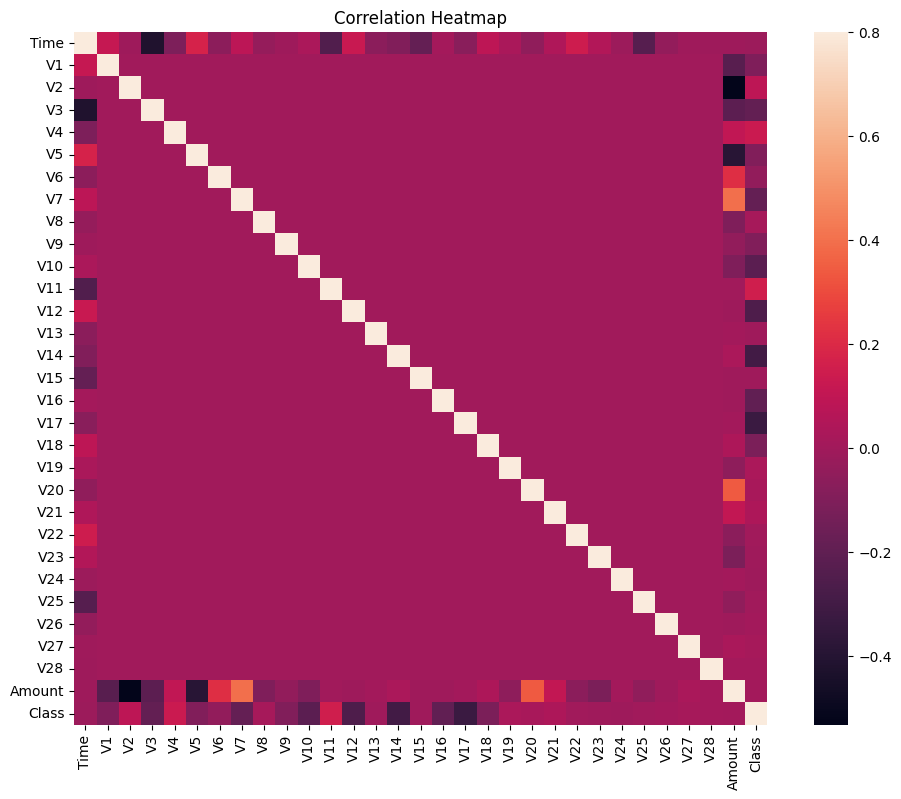

In [16]:
correlation_matrix = data.corr()
plt.figure(figsize=(12, 9))
sns.heatmap(correlation_matrix, vmax=0.8, square=True)
plt.title('Correlation Heatmap')
plt.show()

In [14]:
X = data.drop('Class', axis=1)
Y = data['Class']

x_data = X.values
y_data = Y.values

X_train, X_test, Y_train, Y_test = train_test_split(x_data, y_data, test_size=0.2, random_state=42)

In [15]:
rfc = RandomForestClassifier()
rfc.fit(X_train, Y_train)

Y_pred = rfc.predict(X_test)

In [17]:
print('NaN values in Y_test before imputation:', np.isnan(Y_test).sum())

imputer = SimpleImputer(strategy='most_frequent')
Y_test = imputer.fit_transform(Y_test.reshape(-1, 1)).flatten()

print('NaN values in Y_test after imputation:', np.isnan(Y_test).sum())

NaN values in Y_test before imputation: 0
NaN values in Y_test after imputation: 0


In [19]:
acc = accuracy_score(Y_test, Y_pred)
prec = precision_score(Y_test, Y_pred)
rec = recall_score(Y_test, Y_pred)
f1 = f1_score(Y_test, Y_pred)
mcc = matthews_corrcoef(Y_test, Y_pred)

print(f"Accuracy: {acc}")
print(f"Precision: {prec}")
print(f"Recall: {rec}")
print(f"F1 Score: {f1}")
print(f"MCC: {mcc}")


Accuracy: 0.9995962220427653
Precision: 0.9746835443037974
Recall: 0.7857142857142857
F1 Score: 0.8700564971751412
MCC: 0.8749276812909632


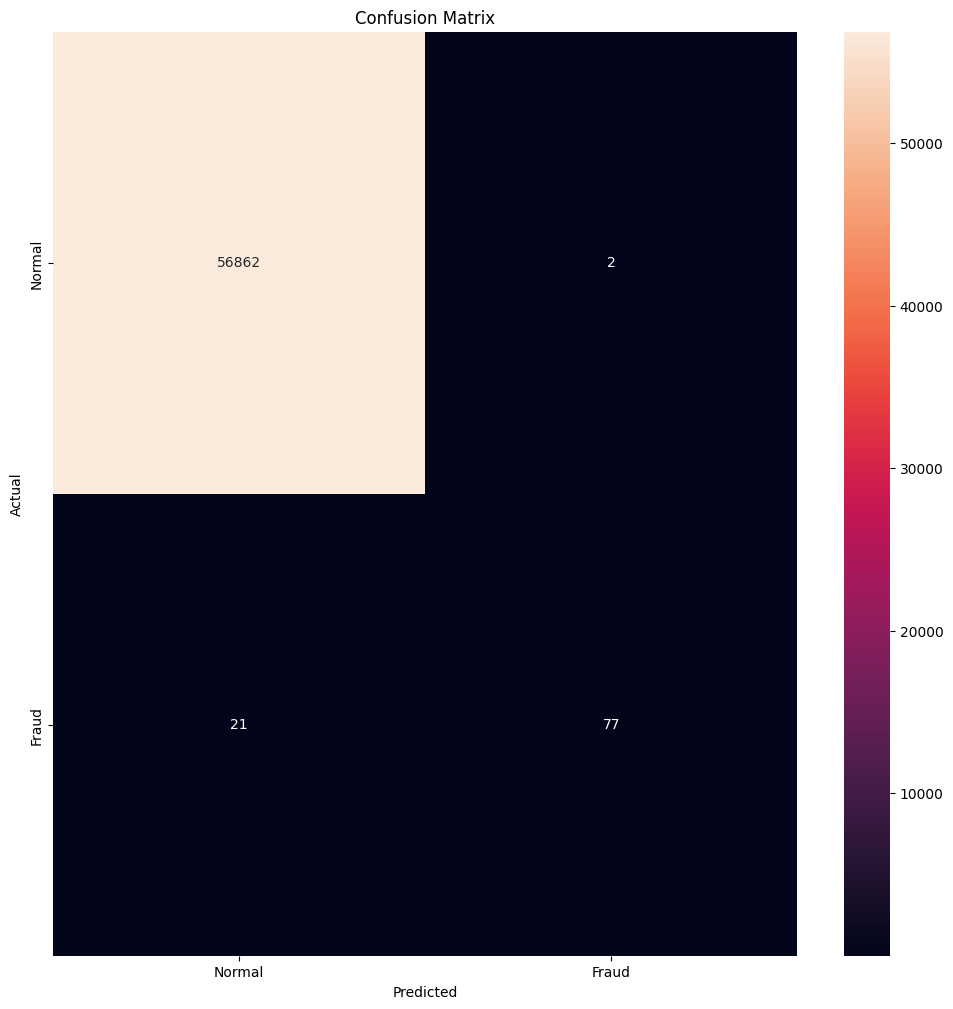

In [20]:
LABELS = ['Normal', 'Fraud']
conf_matrix = confusion_matrix(Y_test, Y_pred)
plt.figure(figsize=(12, 12))
sns.heatmap(conf_matrix, xticklabels=LABELS, yticklabels=LABELS, annot=True, fmt='d')
plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()